In [ ]:
import torch
import torch.nn as nn
from torchvision import transforms, datasets, models
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from torch import optim, cuda
from torch.utils.data import DataLoader, sampler

#Optimalization of hyperparameters
import optuna

# Visualizations
import matplotlib.pyplot as plt
#import seaborn as sns
%matplotlib inline

# Data science tools
import numpy as np
import pandas as pd
import os

import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

# Timing utility
from timeit import default_timer as timer

# Whether to train on a gpu
train_on_gpu = cuda.is_available()
print(f'Train on gpu: {train_on_gpu}')

if train_on_gpu:
    gpu_count = cuda.device_count()
    print(f'{gpu_count} gpus detected.')
    if gpu_count > 1:
        multi_gpu = True
    else:
        multi_gpu = False
torch.cuda.get_device_name(torch.cuda.current_device())

In [2]:
#dodanie folderu z danymi do notebooka
import zipfile as zf
files = zf.ZipFile("chest_data2.zip", 'r')
files.extractall('.')
files.close()

In [6]:
# Przygotowanie transformacji danych
image_transforms = {
    # Train uses data augmentation
    'train':
    transforms.Compose([
        transforms.RandomResizedCrop(size=200, scale=(0.8, 1.0)),
        transforms.RandomRotation(degrees=30),
        transforms.ColorJitter(),
        transforms.RandomHorizontalFlip(),
        transforms.CenterCrop(size=64),  # Image net standards
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406],
                             [0.229, 0.224, 0.225])  # Imagenet standards
    ]),
    # Validation does not use augmentation
    'val':
    transforms.Compose([
        transforms.Resize(size=64),
        transforms.CenterCrop(size=180),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    # Test does not use augmentation
    'test':
    transforms.Compose([
        transforms.Resize(size=64),
        transforms.CenterCrop(size=180),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}

In [7]:
transform = transforms.Compose(
    [transforms.ToTensor()])


batch_size = 5

#pobranie i transformacja danych
data = {
    'train':
    datasets.ImageFolder(root='./train', transform=image_transforms['test']),
    'val':
    datasets.ImageFolder(root='./val', transform=image_transforms['val']),
    'test':
    datasets.ImageFolder(root='./test', transform=image_transforms['test'])
}

#utworzenie loaderów
dataloaders = {
    'train': DataLoader(data['train'], batch_size=batch_size, shuffle=True),
    'val': DataLoader(data['val'], batch_size=batch_size, shuffle=True),
    'test': DataLoader(data['test'], batch_size=batch_size, shuffle=True)
}

n_classes=2

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def create_model(trial):
    
    # Hiperparametry do optymalizacji
    dense_units_1 = trial.suggest_int("dense_units_1", 512, 1024, step=128)
    dense_units_2 = trial.suggest_int("dense_units_2", 256, 512, step=64)
    dropout_rate_1 = trial.suggest_float("dropout_1", 0.0, 0.5)
    dropout_rate_2 = trial.suggest_float("dropout_2", 0.0, 0.5)

    # Pretrenowany model
    model = models.resnet50(pretrained=True)

    # Zamrażanie warstw konwolucyjnych
    for param in model.parameters():
        param.requires_grad = False

    # Zmiana klasyfikatora (fully connected layer)
    num_features = model.fc.in_features
    model.fc = nn.Sequential(
        nn.Linear(2048, 2048), nn.ReLU(), nn.Dropout(dropout_rate_1),
        nn.Linear(num_features, dense_units_1), nn.ReLU(), nn.Dropout(dropout_rate_2),
        nn.Linear(dense_units_1, dense_units_2), nn.ReLU(),
        nn.Linear(dense_units_2, 2), nn.LogSoftmax(dim=1)
    )

    return model.to(device)


# Funkcja celu dla Optuna
def objective(trial):
    # Tworzymy model i hiperparametry
    model = create_model(trial)
    lr = trial.suggest_loguniform("lr", 1e-5, 1e-2)
    batch_size = trial.suggest_categorical("batch_size", [5, 16, 32, 64])

    criterion = nn.NLLLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    #Dane
    train_loader = DataLoader(data['train'], batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(data['val'], batch_size=batch_size)

    #Trening
    num_epochs = 3
    for epoch in range(num_epochs):
        #Trenowanie
        model.train()
        for ii, (x, y) in enumerate(train_loader):
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            loss = criterion(model(x), y)
            loss.backward()
            optimizer.step()

        #Walidacja
        model.eval()
        val_acc = 0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)
                output = model(x)

                # Validation loss
                loss = criterion(output, y)

                # Calculate validation accuracy
                _, pred = torch.max(output, dim=1)
                correct_tensor = pred.eq(y.data.view_as(pred))
                accuracy = torch.mean(
                    correct_tensor.type(torch.FloatTensor))
                # Multiply average accuracy times the number of examples
                val_acc += accuracy.item() * x.size(0)
                
        val_acc = val_acc / len(val_loader.dataset)

        #Pruning: przerywamy, jeśli model idzie źle
        trial.report(val_acc, epoch)
        if trial.should_prune():
            raise optuna.exceptions.TrialPruned()

    return val_acc


#Uruchomienie optymalizacji
study = optuna.create_study(direction="maximize", pruner=optuna.pruners.MedianPruner())
study.optimize(objective, n_trials=100)

print("Najlepsze parametry:")
print(study.best_params)

[I 2025-11-08 11:32:31,031] A new study created in memory with name: no-name-d4bdb353-4966-46ae-a23e-c528e13ec344
C:\Users\Xelor\anaconda3\envs\PyTorchEnv\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\Xelor\anaconda3\envs\PyTorchEnv\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
[I 2025-11-08 11:38:03,927] Trial 0 finished with value: 0.9375000037252903 and parameters: {'dense_units_1': 1024, 'dense_units_2': 448, 'dropout_1': 0.07580980061444398, 'dropout_2': 0.26677531071895516, 'lr': 5.19924396968

Najlepsze parametry:
{'dense_units_1': 1024, 'dense_units_2': 448, 'dropout_1': 0.07580980061444398, 'dropout_2': 0.26677531071895516, 'lr': 5.1992439696844757e-05, 'batch_size': 5}


In [4]:
def get_pretrained_model():

    #mv - modyfication version, wersja modyfikacji końcowych warstw sieci
    
    model = models.resnet50(pretrained=True)

    # Freeze early layers
    for param in model.parameters():
        param.requires_grad = False
    n_inputs = model.fc.in_features

   
    # Add on fc
    model.fc = nn.Sequential(
    nn.Linear(2048, 2048), nn.ReLU(), nn.Dropout(0.24308290063912166),
    nn.Linear(n_inputs, 1024), nn.ReLU(), nn.Dropout(0.006558555396851379),
    nn.Linear(1024, 512), nn.ReLU(),
    nn.Linear(512, n_classes), nn.LogSoftmax(dim=1))

    # Move to gpu and parallelize
    if train_on_gpu:
        model = model.to('cuda')

    return model

In [17]:
model = get_pretrained_model()

C:\Users\Xelor\anaconda3\envs\PyTorchEnv\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\Xelor\anaconda3\envs\PyTorchEnv\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [16]:
#Struktura sieci
#model

In [18]:
#Mapowanie indeksów do klas
model.class_to_idx = data['train'].class_to_idx
model.idx_to_class = {
    idx: class_
    for class_, idx in model.class_to_idx.items()
}

list(model.idx_to_class.items())[:10]

[(0, 'NORMAL'), (1, 'PNEUMONIA')]

In [19]:
#Ustalenie optymalizatora i funkcji straty
criterion = nn.NLLLoss()
optimizer = optim.Adam(model.parameters(),lr=0.00017052484024718956)

In [20]:
#Sprawdzenie rozłożenia wejść w poszczególnych warstwach
for p in optimizer.param_groups[0]['params']:
    if p.requires_grad:
        print(p.shape)

torch.Size([2048, 2048])
torch.Size([2048])
torch.Size([1024, 2048])
torch.Size([1024])
torch.Size([512, 1024])
torch.Size([512])
torch.Size([2, 512])
torch.Size([2])


In [9]:
def train(model,criterion,optimizer,train_loader,valid_loader,save_file_name, history=[],
          max_epochs_stop=3,n_epochs=20,print_every=1):
    """Train a PyTorch Model

    Params
    --------
        model (PyTorch model): cnn to train
        criterion (PyTorch loss): objective to minimize
        optimizer (PyTorch optimizier): optimizer to compute gradients of model parameters
        train_loader (PyTorch dataloader): training dataloader to iterate through
        valid_loader (PyTorch dataloader): validation dataloader used for early stopping
        save_file_name (str ending in '.pt'): file path to save the model state dict
        max_epochs_stop (int): maximum number of epochs with no improvement in validation loss for early stopping
        n_epochs (int): maximum number of training epochs
        print_every (int): frequency of epochs to print training stats

    Returns
    --------
        model (PyTorch model): trained cnn with best weights
        history (DataFrame): history of train and validation loss and accuracy
        epochs (Number): number of epochs trained
    """

    # Early stopping intialization
    epochs_no_improve = 0
    valid_loss_min = np.inf
    valid_max_acc = 0

    if isinstance(history, pd.DataFrame):
        idx=history['valid_loss'].idxmin()
        
        valid_loss_min=history.iloc[history['valid_loss'].idxmin()][1]
        valid_best_acc=history.iloc[history['valid_loss'].idxmin()][3]
        history = torch.tensor(history.values).tolist()
        best_epoch=idx+1
    else:
        history=history
        

    # Number of epochs already trained (if using loaded in model weights)
    try:
        print(f'Model has been trained for: {model.epochs} epochs.\n')
    except:
        model.epochs = 0
        print(f'Starting Training from Scratch.\n')

    overall_start = timer()

    # Main loop
    for epoch in range(n_epochs):

        # keep track of training and validation loss each epoch
        train_loss = 0.0
        valid_loss = 0.0

        train_acc = 0
        valid_acc = 0

        # Set to training
        model.train()
        start = timer()

        # Training loop
        for ii, (data, target) in enumerate(train_loader):
            # Tensors to gpu
            if train_on_gpu:
                data, target = data.cuda(), target.cuda()

            # Clear gradients
            optimizer.zero_grad()
            # Predicted outputs are log probabilities
            output = model(data)

            # Loss and backpropagation of gradients
            loss = criterion(output, target)
            
            loss.backward()

            # Update the parameters
            optimizer.step()

            # Track train loss by multiplying average loss by number of examples in batch
            train_loss += loss.item() * data.size(0)

            # Calculate accuracy by finding max log probability
            _, pred = torch.max(output, dim=1)
            correct_tensor = pred.eq(target.data.view_as(pred))
            # Need to convert correct tensor from int to float to average
            accuracy = torch.mean(correct_tensor.type(torch.FloatTensor))
            # Multiply average accuracy times the number of examples in batch
            train_acc += accuracy.item() * data.size(0)

            # Track training progress
            print(
                f'Epoch: {model.epochs+1}\t{100 * (ii + 1) / len(train_loader):.2f}% complete. {timer() - start:.2f} seconds elapsed in epoch.',
                end='\r')

        # After training loops ends, start validation
        
        model.epochs += 1

        # Don't need to keep track of gradients
        with torch.no_grad():
            # Set to evaluation mode
            model.eval()

            # Validation loop
            for data, target in valid_loader:
                # Tensors to gpu
                if train_on_gpu:
                    data, target = data.cuda(), target.cuda()

                # Forward pass
                output = model(data)

                # Validation loss
                loss = criterion(output, target)
                # Multiply average loss times the number of examples in batch
                valid_loss += loss.item() * data.size(0)

                # Calculate validation accuracy
                _, pred = torch.max(output, dim=1)
                correct_tensor = pred.eq(target.data.view_as(pred))
                accuracy = torch.mean(
                    correct_tensor.type(torch.FloatTensor))
                # Multiply average accuracy times the number of examples
                valid_acc += accuracy.item() * data.size(0)

            # Calculate average losses
            train_loss = train_loss / len(train_loader.dataset)
            valid_loss = valid_loss / len(valid_loader.dataset)

            # Calculate average accuracy
            train_acc = train_acc / len(train_loader.dataset)
            valid_acc = valid_acc / len(valid_loader.dataset)

            history.append([train_loss, valid_loss, train_acc, valid_acc])

            # Print training and validation results
            if (model.epochs) % print_every == 0:
                print(
                    f'\nEpoch: {model.epochs} \tTraining Loss: {train_loss:.4f} \tValidation Loss: {valid_loss:.4f}'
                )
                print(
                    f'\t\tTraining Accuracy: {100 * train_acc:.2f}%\t Validation Accuracy: {100 * valid_acc:.2f}%'
                )

            if valid_loss < 0:
                # Save the model if validation loss decreases
                if (valid_loss *(-1)) < valid_loss_min:
                    # Save model
                    torch.save(model.state_dict(), save_file_name)
                    # Track improvement
                    epochs_no_improve = 0
                    valid_loss_min = valid_loss
                    valid_best_acc = valid_acc
                    best_epoch = model.epochs

                # Otherwise increment count of epochs with no improvement
                else:
                    epochs_no_improve += 1
                    # Trigger early stopping
                    if epochs_no_improve >= max_epochs_stop:
                        print(
                            f'\nEarly Stopping! Total epochs: {epoch+1}. Best epoch: {best_epoch} with loss: {valid_loss_min:.2f} and acc: {100 * valid_acc:.2f}%'
                        )
                        total_time = timer() - overall_start
                        print(
                            f'{total_time:.2f} total seconds elapsed. {total_time / (epoch+1):.2f} seconds per epoch.'
                        )

                        # Load the best state dict
                        model.load_state_dict(torch.load(save_file_name))
                        # Attach the optimizer
                        model.optimizer = optimizer

                        # Format history
                        history = pd.DataFrame(
                            history,
                            columns=[
                                'train_loss', 'valid_loss', 'train_acc',
                                'valid_acc'
                            ])
                        return model, history, epoch+1
            else:
                # Save the model if validation loss decreases
                if valid_loss < valid_loss_min:
                    # Save model
                    torch.save(model.state_dict(), save_file_name)
                    # Track improvement
                    epochs_no_improve = 0
                    valid_loss_min = valid_loss
                    valid_best_acc = valid_acc
                    best_epoch = model.epochs

                # Otherwise increment count of epochs with no improvement
                else:
                    epochs_no_improve += 1
                    # Trigger early stopping
                    if epochs_no_improve >= max_epochs_stop:
                        print(
                            f'\nEarly Stopping! Total epochs: {epoch+1}. Best epoch: {best_epoch} with loss: {valid_loss_min:.2f} and acc: {100 * valid_best_acc:.2f}%'
                        )
                        total_time = timer() - overall_start
                        print(
                            f'{total_time:.2f} total seconds elapsed. {total_time / (epoch+1):.2f} seconds per epoch.'
                        )

                        # Load the best state dict
                        model.load_state_dict(torch.load(save_file_name))
                        # Attach the optimizer
                        model.optimizer = optimizer

                        # Format history
                        history = pd.DataFrame(
                            history,
                            columns=[
                                'train_loss', 'valid_loss', 'train_acc',
                                'valid_acc'
                            ])
                        return model, history, epoch+1

    # Attach the optimizer
    model.optimizer = optimizer
    # Record overall time and print out stats
    total_time = timer() - overall_start
    print(
        f'\nBest epoch: {best_epoch} with loss: {valid_loss_min:.2f} and acc: {100 * valid_best_acc:.2f}%'
    )
    if(epoch<=0):
        epoch=1
    print(
        f'{total_time:.2f} total seconds elapsed. {total_time / (epoch):.2f} seconds per epoch.'
    )
    # Format history
    history = pd.DataFrame(
        history,
        columns=['train_loss', 'valid_loss', 'train_acc', 'valid_acc'])
    return model, history, n_epochs

In [4]:
def save_checkpoint(model, history, path):
    """Save a PyTorch model checkpoint

    Params
    --------
        model (PyTorch model): model to save
        path (str): location to save model.

    Returns
    --------
        None, save the `model` to `path`

    """

    # Basic details
    checkpoint = {
        'class_to_idx': model.class_to_idx,
        'idx_to_class': model.idx_to_class,
        'epochs': model.epochs,
    }

    if multi_gpu:
        checkpoint['fc'] = model.fc
        checkpoint['state_dict'] = model.module.state_dict()
    else:
        checkpoint['fc'] = model.fc
        checkpoint['state_dict'] = model.state_dict()

    # Add the optimizer
    checkpoint['optimizer'] = model.optimizer
    checkpoint['optimizer_state_dict'] = model.optimizer.state_dict()

    #Add the history
    checkpoint['history'] = history

    # Save the data to the path
    torch.save(checkpoint, path)


In [8]:
def load_checkpoint(path):
    """Load a PyTorch model checkpoint

    Params
    --------
        path (str): saved model checkpoint.

    Returns
    --------
        None, save the `model` to `path`

    """

    # Load in checkpoint
    checkpoint = torch.load(path)

    model = models.resnet50(pretrained=True)
    # Make sure to set parameters as not trainable
    for param in model.parameters():
        param.requires_grad = False
    model.fc = checkpoint['fc']

    # Load in the state dict
    model.load_state_dict(checkpoint['state_dict'])

    total_params = sum(p.numel() for p in model.parameters())
    print(f'{total_params:,} total parameters.')
    total_trainable_params = sum(
        p.numel() for p in model.parameters() if p.requires_grad)
    print(f'{total_trainable_params:,} total gradient parameters.')

    # Move to gpu
    if train_on_gpu:
        model = model.to('cuda')

    # Model basics
    model.class_to_idx = checkpoint['class_to_idx']
    model.idx_to_class = checkpoint['idx_to_class']
    model.epochs = checkpoint['epochs']

    # Optimizer
    optimizer = checkpoint['optimizer']
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])

    # History
    history=checkpoint['history']

    return model, history, optimizer

In [9]:
save_file_name = 'resnet50_umwdm.pt'
checkpoint_path = 'resnet50_umwdm.pth'

In [21]:
history=[]
n_epochs=20

while n_epochs > 0:
    model, history, epoch = train(
        model,
        criterion,
        optimizer,
        dataloaders['train'],
        dataloaders['test'],
        save_file_name=save_file_name,
        history=history,
        max_epochs_stop=3,
        n_epochs=n_epochs,
        print_every=1)
    n_epochs-=epoch
    print("-------------------------------")

Starting Training from Scratch.

Epoch: 1	100.00% complete. 120.96 seconds elapsed in epoch.
Epoch: 1 	Training Loss: 0.4085 	Validation Loss: 0.5576
		Training Accuracy: 81.39%	 Validation Accuracy: 78.04%
Epoch: 2	100.00% complete. 124.30 seconds elapsed in epoch.
Epoch: 2 	Training Loss: 0.3378 	Validation Loss: 0.5308
		Training Accuracy: 86.32%	 Validation Accuracy: 79.17%
Epoch: 3	100.00% complete. 122.90 seconds elapsed in epoch.
Epoch: 3 	Training Loss: 0.2970 	Validation Loss: 0.5690
		Training Accuracy: 87.81%	 Validation Accuracy: 78.21%
Epoch: 4	100.00% complete. 120.77 seconds elapsed in epoch.
Epoch: 4 	Training Loss: 0.2918 	Validation Loss: 0.5605
		Training Accuracy: 87.66%	 Validation Accuracy: 79.97%
Epoch: 5	100.00% complete. 120.12 seconds elapsed in epoch.
Epoch: 5 	Training Loss: 0.2954 	Validation Loss: 0.4810
		Training Accuracy: 88.07%	 Validation Accuracy: 81.89%
Epoch: 6	100.00% complete. 119.96 seconds elapsed in epoch.
Epoch: 6 	Training Loss: 0.2851 	Vali

In [22]:
print(history)

    train_loss  valid_loss  train_acc  valid_acc
0     0.408461    0.557628   0.813945   0.780449
1     0.337816    0.530798   0.863162   0.791667
2     0.296953    0.569018   0.878076   0.782051
3     0.291759    0.560508   0.876585   0.799679
4     0.295394    0.481005   0.880686   0.818910
5     0.285077    0.527600   0.883669   0.793269
6     0.289870    0.516871   0.882550   0.793269
7     0.277178    0.442540   0.887025   0.804487
8     0.256647    0.522792   0.900820   0.793269
9     0.289799    0.565953   0.884415   0.810897
10    0.284798    0.524080   0.882923   0.841346
11    0.284242    0.483408   0.881805   0.826923
12    0.294489    0.685202   0.879940   0.761218
13    0.260731    0.639863   0.894482   0.764423
14    0.295311    0.564509   0.877330   0.804487
15    0.299020    0.399965   0.871365   0.831731
16    0.277239    0.488415   0.884415   0.802885
17    0.281671    0.458614   0.893363   0.809295
18    0.263576    0.554004   0.892245   0.804487
19    0.281476    0.

Text(0.5, 1.0, 'Training and Validation Losses')

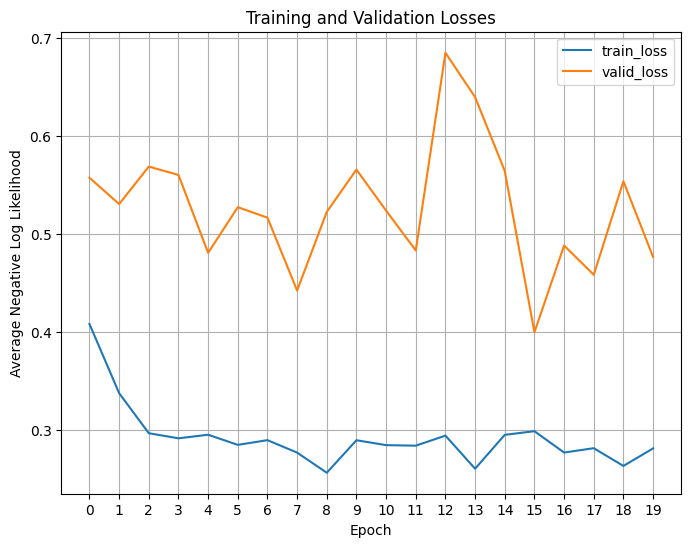

In [23]:
plt.figure(figsize=(8, 6))
plt.xticks(range(0, len(history)))
for c in ['train_loss', 'valid_loss']:
    plt.plot(
        history[c], label=c)
plt.grid()
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Average Negative Log Likelihood')
plt.title('Training and Validation Losses')

Text(0.5, 1.0, 'Training and Validation Accuracy')

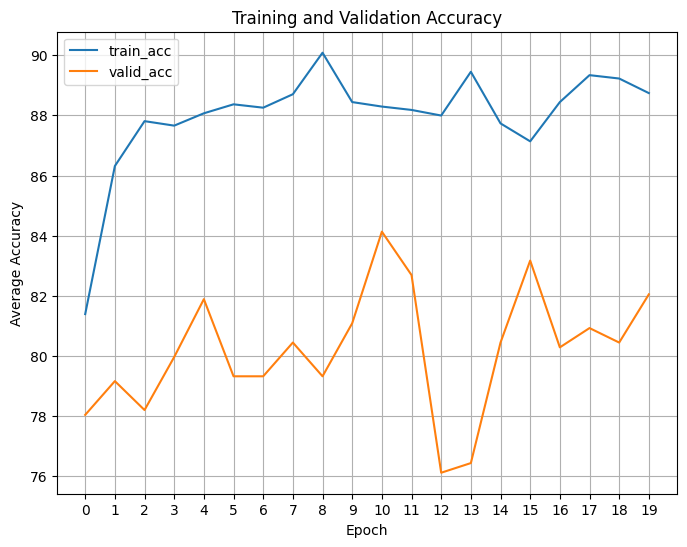

In [24]:
plt.figure(figsize=(8, 6))
plt.xticks(range(0, len(history)))
for c in ['train_acc', 'valid_acc']:
    plt.plot(
        100 * history[c], label=c)
plt.grid()
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Average Accuracy')
plt.title('Training and Validation Accuracy')

In [25]:
save_checkpoint(model, history, path=checkpoint_path)

In [10]:
model, history, optimizer = load_checkpoint(path=checkpoint_path)

C:\Users\Xelor\anaconda3\envs\PyTorchEnv\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\Xelor\anaconda3\envs\PyTorchEnv\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


30,328,386 total parameters.
6,820,354 total gradient parameters.
